# **3. 슬롯머신 AI 개발**
- 가장 많은 보상을 획득하는 AI 에이전트 만들기
- 카지노에 있는 5개의 슬롯머신 중 가장 높은 당첨 확률을 가진 머신을 스스로 찾아내는 AI 프로그램을 개발
- 각 슬롯머신은 서로 다른 당첨 확률을 가지고 있지만, AI 에이전트는 어떤 머신이 가장 유리한지 알지 못함
- 에이전트는 슬롯머신을 직접 선택하고, 당첨 여부를 확인하면서 각 머신의 당첨 확률을 추정해야함
- 최종 목표는 1000번의 행동동안 가능한 많은 보상을 획득하는 것


### 3-1. 슬롯머신 환경 구현
- Python과 Numpy 사용
- 슬롯머신은 총 5개
- 실제 당첨 확률은 [0.2, 0.5, 0.1, 0.8, 0.3]으로 설정
- 슬롯머신을 선택하면 당첨시 1, 실패시 0의 보상을 반환하도록 구현
- AI 에이전트는 실제 당첨 확률을 직접 참조해서 행동하면 안됨

### 3-2. AI 에이전트 구현
- Random 전략: 5ro=개의 슬롯머신 중 하나를 무작위로 선택
- Greedy 전략: 지금까지 획득한 보상을 기반으로 가장 높은 평균 보상을 가진 슬롯머신 선택
- ε-greedy 전략: 일정 확률로 무작위 슬롯머신을 선택하고, 나머지 확률로 현재 가장 높은 평균 보상을 가진 슬롯머신을 선택(ε값은 0.1과 0.01을 각각 적용)

### 3-3. 학습 기능 구현
AI 에이전트는 슬롯머신을 선택할ㄹ때마다 아래 정보를 업데이트 해야하마
- 각 슬롯머신을 선택한 횟수
- 각 슬롯머신의 평균 보상 추정 값
- 매 행동에서 획득한 보상
- 지금까지 획득한 누적 보상

> 평균 보상은 기준 데이터를 모두 다시 계산하지 않고, 이전 평균과 새로 획득한 보상을 이용하는 방식으로 구현

### 3-4. 전략별 실험
각 전략을 1000번씩 실행하고 아래 결과를 출력
- 최종 누적 보상
- 슬롯머신별 선택 횟수
- 슬롯머신별 추정 당첨 확률
- 가장 많이 선택한 슬롯머신 번호

In [1]:
import numpy as np

In [2]:
# 슬롯머신 5개의 실제 당첨 확률
WIN_PROBS = np.array([0.2, 0.5, 0.1, 0.8, 0.3])

In [3]:
# 난수 생성기
rng = np.random.default_rng(42)

In [4]:
# 선택한 슬롯머신의 보상 반환
def play_slot(machine):
    prob = WIN_PROBS[machine]

    if rng.random() < prob:
        return 1
    else:
        return 0

In [5]:
# 랜덤 선택
def select_random():
    return int(rng.integers(0, 5))

# Greedy: 평균 보상이 가장 높은 머신 선택
def select_greedy(q_values):
    return int(np.argmax(q_values))

# ε-greedy: 탐험 + 활용
def select_epsilon_greedy(q_values, epsilon):
    if rng.random() < epsilon:
        return select_random()        # 탐험
    else:
        return select_greedy(q_values)  # 활용

In [6]:
def run_experiment(strategy, steps=1000, epsilon=0.1):
    # 슬롯머신별 선택 횟수
    counts = np.zeros(5, dtype=int)

    # 슬롯머신별 평균 보상 추정
    q_values = np.zeros(5)

    # 매번 받은 보상 기록
    rewards = []

    # 누적 보상 기록
    cumulative_rewards = []
    total_reward = 0

    for step in range(steps):

        # 1. 행동 선택
        if strategy == "random":
            machine = select_random()

        elif strategy == "greedy":
            machine = select_greedy(q_values)

        elif strategy == "epsilon_greedy":
            machine = select_epsilon_greedy(q_values, epsilon)

        else:
            raise ValueError("알 수 없는 전략입니다.")

        # 2. 선택한 슬롯머신 실행
        reward = play_slot(machine)

        # 3. 선택 횟수 업데이트
        counts[machine] += 1

        # 4. 평균 보상 업데이트
        n = counts[machine]

        q_values[machine] += (
            reward - q_values[machine]
        ) / n

        # 5. 보상 기록
        total_reward += reward
        rewards.append(reward)
        cumulative_rewards.append(total_reward)

    return counts, q_values, rewards, cumulative_rewards

In [7]:
strategies = [
    ("Random", "random", 0),
    ("Greedy", "greedy", 0),
    ("ε-greedy 0.1", "epsilon_greedy", 0.1),
    ("ε-greedy 0.01", "epsilon_greedy", 0.01),
]

for name, strategy, epsilon in strategies:
    counts, q_values, rewards, cumulative = run_experiment(
        strategy=strategy,
        steps=1000,
        epsilon=epsilon
    )

    print(f"\n===== {name} =====")
    print("최종 누적 보상:", cumulative[-1])
    print("슬롯머신별 선택 횟수:", counts)
    print("추정 당첨 확률:", np.round(q_values, 3))
    print("가장 많이 선택한 슬롯머신:", np.argmax(counts) + 1)


===== Random =====
최종 누적 보상: 394
슬롯머신별 선택 횟수: [194 189 200 195 222]
추정 당첨 확률: [0.222 0.55  0.095 0.836 0.293]
가장 많이 선택한 슬롯머신: 5

===== Greedy =====
최종 누적 보상: 195
슬롯머신별 선택 횟수: [1000    0    0    0    0]
추정 당첨 확률: [0.195 0.    0.    0.    0.   ]
가장 많이 선택한 슬롯머신: 1

===== ε-greedy 0.1 =====
최종 누적 보상: 677
슬롯머신별 선택 횟수: [ 41 277  27 634  21]
추정 당첨 확률: [0.195 0.523 0.074 0.817 0.19 ]
가장 많이 선택한 슬롯머신: 4

===== ε-greedy 0.01 =====
최종 누적 보상: 773
슬롯머신별 선택 횟수: [ 48   1   2 945   4]
추정 당첨 확률: [0.188 0.    0.    0.807 0.25 ]
가장 많이 선택한 슬롯머신: 4


### 내 설명
1. Random: 무작위 슬롯머신 선택
2. Greedy: 현재까지 평균보상 가장 높은 머신 선택
3. 시그마-greedy: 일정 확률로 새 머신 탐색, 나머지는 평균보상이 가장 높은 머신 선택

슬롯머신 선택 시 선택횟수와 평균 보상 추정값 업데이트됨

각 전략 1000번씩 실행하고 누적보상, 슬롯머신별 선택횟수, 추정당첨확률 비교

- for문: 슬롯버신 여러번 실행 시 사용 (반복)
- if문: 조건에 따라 어떤 슬롯머신 선택할지 결정 (조건 판단)
- rng.integers(): 슬롯머신 번호 무작위 선택(난수생성)

___
# **5. 상태 전이와 할인 보상 계산**
- 일상생활에서 행동을 선택하는 AI 에이전트를 개발하려고 함
- 에이전트는 Working(공부), gym(운동), home(귀가) 세가지 상태를 가지며, 선택한 행동에 따라 상태 변경되고 보상방음

```
현재 상태	행동		다음 상태	보상
working		working		working		+3
working		gym		gym		+5
working		home		home		+12
gym		working		working		+4
gym		home		home		+12
```

### **5-1. 구현 요구시항**
- 상태 전이와 보상을 저장하는 딕셔너리를 작성
- 행동 목록과 할인율을 전달받는 함수 구현
- 시작 상태는 working으로 설정
- 행동을 순서대로 실행하며 상태를 변경하고 보상 저장
- 불가능한 행동을 선택하거나 종료 상태에서 추가 행동을 실행하면 오류가 발생하도록 구현
- 아래 공식을 사용해 할인 리턴율 계산

$
G = R_1 + γR_2 + γ^2R_3 + ...
$

- 할인율을 기본적으로 0.9를 사용
- 두 가지 경로를 실행하고 결과를 비교
    - working > working > home
    - gym > working > home

In [8]:
# 상태 전이 및 보상 정의
transitions = {
    "working": {
        "working": ("working", 3),
        "gym": ("gym", 5),
        "home": ("home", 12)
    },
    "gym": {
        "working": ("working", 4),
        "home": ("home", 12)
    },
    "home": {}
}

In [9]:
# 상태 전이 확인
next_state, reward = transitions["working"]["gym"]

print("다음 상태:", next_state)
print("보상:", reward)

다음 상태: gym
보상: 5


In [10]:
# 상태 전이 함수
def run_episode(actions):
    state = "working"  # 시작 상태
    rewards = []

    for action in actions:
        # 현재 상태에서 선택할 수 없는 행동인지 확인
        if action not in transitions[state]:
            raise ValueError(f"{state}에서 {action} 행동은 불가능합니다.")

        # 다음 상태와 보상 가져오기
        next_state, reward = transitions[state][action]

        print(f"{state} → {action} → {next_state} | 보상: +{reward}")

        rewards.append(reward)
        state = next_state

    return rewards

In [11]:
# 두개 경로 실행
path1 = ["working", "working", "home"]
path2 = ["gym", "working", "home"]

print("=== 경로 1 ===")
rewards1 = run_episode(path1)

print("\n=== 경로 2 ===")
rewards2 = run_episode(path2)

=== 경로 1 ===
working → working → working | 보상: +3
working → working → working | 보상: +3
working → home → home | 보상: +12

=== 경로 2 ===
working → gym → gym | 보상: +5
gym → working → working | 보상: +4
working → home → home | 보상: +12


In [12]:
# 할인률 적용
def calculate_return(rewards, gamma=0.9):
    return sum(
        (gamma ** t) * reward
        for t, reward in enumerate(rewards)
    )

print("경로 1 Return:", calculate_return(rewards1))
print("경로 2 Return:", calculate_return(rewards2))

경로 1 Return: 15.420000000000002
경로 2 Return: 18.32


### 내 설명
- transitions: 상태별 행동, 다음 상태, 보상을 딕셔너리로 정의
- run_episode(): 행동 목록을 순서대로 실행하고 보상을 저장
- rewards.append(): 행동으로 얻은 보상을 리스트에 추가
- calculate_return(): 할인율 γ=0.9를 적용해 누적 할인 보상(Return) 계산

- 경로1 계산식: 3 + 0.9 × 3 + 0.9² × 12 = 15.42     # working → working → home
- 경로2 계산식: 5 + 0.9 × 4 + 0.9² × 12 = 18.32     # working → gym → working → home

할인율을 적용하면 미래 보상에 가중치를 다르게 주어 경로별 Return을 비교가능

> 두 경로 비교 결과, 두번째 경로 Return이 2.90점 더 높음

___
# **7. 집으로 돌아가는 길**
한 학생이 집으로 돌아가려고 합니다. 현재 위치는 A, B, C중 하나이며, 이동하다 보면 집(Home)에 도착하거나 술집(Bar)에 도착할 수 있습니다. 각 위치에서 다음 위치로 이동할 확률은 미리 정해져있으며, 학생은 이동 방향을 직접 선택할 수 없습니다, 이 환경에서 각 위치가 얼마나 유리한 상태인지 계산하는 프로그램을 작성하세요.

### **7-1. 이동규칙**
```
확률

현재위치        다음위치        이동확률
A               Home            70%
A               B               30%
B               A               50%
B               C               50%
C               B               50%
C               Bar             50%
```

Home과 Bar에 도착 시 이동 종료

보상규칙
- Home 도착 시 +10
- Bar 도착 시 -10
- 그 외 이동 0
- 할인률 0.9


### **7-2. 문제**
- 상태 목록 STATES, 이동 규칙 NEXT, 종료 상태 TERMINAL을 정의
- 다음 위치가 Home이면 +10, Bar이면 -10, 그 외에는 0을 반환하는 함수 작성
- 모든 상태의 가치 0으로 초기화한 후 벨만 기대 방정식 이용해 각 상태의 가치 계산
- 최대 100회 반복. 매 반복하마 A, B, C의 가치를 갱신. 이전 반복과 현재 반복의 최대 가치 차이를 계산. 반복에 따라 가치 변화 출력

### **7-3. 답 할 내용**
1. A, B, C 중 가치가 가장 높은 상태는 어디인가요?
2. A의 가치가 B보다 높은 이유는 무엇인가요?
3. C의 가치가 음수가 되는 이유는 무엇인가요?
4. 반복할수록 가치 변화량이 작아지는 이유는 무엇인가요?
5. 할인율을 0.9에서 1로 변경하면 결과가 어떻게 달라지나요?

In [13]:
STATES = ["A", "B", "C", "Home", "Bar"]

TERMINAL = ["Home", "Bar"]

GAMMA = 0.9

In [14]:
NEXT = {
    "A": [("Home", 0.7), ("B", 0.3)],
    "B": [("A", 0.5), ("C", 0.5)],
    "C": [("B", 0.5), ("Bar", 0.5)],
    "Home": [],
    "Bar": []
}

In [15]:
def get_reward(next_state):
    if next_state == "Home":
        return 10
    elif next_state == "Bar":
        return -10
    else:
        return 0

In [16]:
print(get_reward("Home"))  # 10
print(get_reward("Bar"))   # -10
print(get_reward("B"))     # 0

10
-10
0


In [17]:
V = {state: 0.0 for state in STATES}

print(V)

{'A': 0.0, 'B': 0.0, 'C': 0.0, 'Home': 0.0, 'Bar': 0.0}


In [18]:
MAX_ITER = 100

for i in range(MAX_ITER):
    new_V = V.copy()

    for state in ["A", "B", "C"]:
        value = 0

        for next_state, prob in NEXT[state]:
            reward = get_reward(next_state)

            value += prob * (reward + GAMMA * V[next_state])

        new_V[state] = value

    # 이전 반복과 현재 반복의 최대 가치 차이
    delta = max(
        abs(new_V[state] - V[state])
        for state in ["A", "B", "C"]
    )

    V = new_V

    print(
        f"{i+1}회 | "
        f"A: {V['A']:.4f}, "
        f"B: {V['B']:.4f}, "
        f"C: {V['C']:.4f} | "
        f"변화량: {delta:.6f}"
    )

1회 | A: 7.0000, B: 0.0000, C: -5.0000 | 변화량: 7.000000
2회 | A: 7.0000, B: 0.9000, C: -5.0000 | 변화량: 0.900000
3회 | A: 7.2430, B: 0.9000, C: -4.5950 | 변화량: 0.405000
4회 | A: 7.2430, B: 1.1916, C: -4.5950 | 변화량: 0.291600
5회 | A: 7.3217, B: 1.1916, C: -4.4638 | 변화량: 0.131220
6회 | A: 7.3217, B: 1.2861, C: -4.4638 | 변화량: 0.094478
7회 | A: 7.3472, B: 1.2861, C: -4.4213 | 변화량: 0.042515
8회 | A: 7.3472, B: 1.3167, C: -4.4213 | 변화량: 0.030611
9회 | A: 7.3555, B: 1.3167, C: -4.4075 | 변화량: 0.013775
10회 | A: 7.3555, B: 1.3266, C: -4.4075 | 변화량: 0.009918
11회 | A: 7.3582, B: 1.3266, C: -4.4030 | 변화량: 0.004463
12회 | A: 7.3582, B: 1.3298, C: -4.4030 | 변화량: 0.003213
13회 | A: 7.3591, B: 1.3298, C: -4.4016 | 변화량: 0.001446
14회 | A: 7.3591, B: 1.3309, C: -4.4016 | 변화량: 0.001041
15회 | A: 7.3593, B: 1.3309, C: -4.4011 | 변화량: 0.000469
16회 | A: 7.3593, B: 1.3312, C: -4.4011 | 변화량: 0.000337
17회 | A: 7.3594, B: 1.3312, C: -4.4010 | 변화량: 0.000152
18회 | A: 7.3594, B: 1.3313, C: -4.4010 | 변화량: 0.000109
19회 | A: 7.3595, B:

In [19]:
print("===== 최종 상태가치 ======")

for state in ["A", "B", "C"]:
    print(f"{state}: {V[state]:.4f}")

best_state = max(["A", "B", "C"], key=lambda s: V[s])

print("가치가 가장 높은 상태:", best_state)

===== 최종 상태가치 ======
A: 7.3595
B: 1.3314
C: -4.4009
가치가 가장 높은 상태: A


### 내 정리
1. A, B, C 중 가장 가치가 높은 상태?
    - A : 70% 확률로 Home 도착 +10 보상 받음
2. A 가치 B 보다 높은 이유?
    - A는 Home으로 바로 이동할 확률 70%, B는 A또는 C로만 이동이 가능하니까
    - 즉, A가 상대적으로 긍정적 보상을 빠르게 받을 가능성 높음
3. C의 가치가 음수가 되는 이유?
    - C에선 50% 확률로 Bar에 도착 후 -10
    - Bar에 도착할 위험을 고려하면 기대ㅏ치 음수됨
4. 반복할수록 가치 변화량 작아지는 이유?
    - 이전 반복에서 구한 상태가치를 다음 계산에 반영하기 때문
    - 할인률 0.9로 먼 미래의 영향은 점점 작아지고, 계산값은 일정한 값으로 수렴됨
    - A, B, C 가치가 서로 영향 주는데
        - 처음엔 값이 크게 변하지만, 반복할수록 서로 안정되기때문에 변화량이 작아짐 -> 이걸 수렴이라 함
5. 할인율 0.9 > 1로 변경?
    - 미래 보상 할인하지 않음
    - 시간이 지나서 받는 보상도 즉시 받는 보상과 같은 비중으로 계산하게 됨
    - 할인률이 커질수록 미래에 받을 보상을 더 중요하게 생각한다는 뜻
        - γ = 0.5 → 미래 보상을 많이 할인함
        - γ = 0.9 → 미래 보상을 조금 할인함
        - γ = 1.0 → 미래 보상을 할인하지 않음

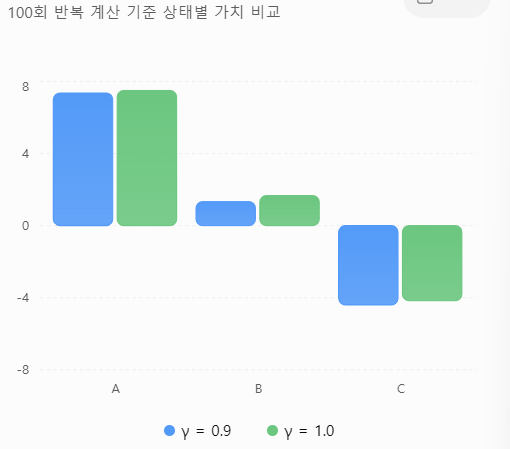

___
# **9. 5*5 격자**
- (0, 0)은 Home: 도착 시 +1
- (0, 4)는 Bar: 도착 시 -1
- 나머지 칸에서 상/하/좌/우로 이동
- 격자 밖이면 제자리
- 목표 칸에 도착하면 즉시 종료, 종료 상태 가치는 0
- 할인율=0.95: 끝나지 않는 정책에도 계산이 안정적으로 수렴하도록 설정

![문제 격자 환경 정의](./images/ref/02_11.png)

In [ ]:
SIZE = 5
GAMMA = 0.95

HOME = (0, 0)
BAR = (0, 4)

TERMINAL = {HOME, BAR}

STATES = [
    (r, c)
    for r in range(SIZE)
    for c in range(SIZE)
]

In [21]:
ACTIONS = {
    "up": (-1, 0),
    "down": (1, 0),
    "left": (0, -1),
    "right": (0, 1)
}

In [22]:
def move(state, action):
    if state in TERMINAL:
        return state

    r, c = state
    dr, dc = ACTIONS[action]

    nr = r + dr
    nc = c + dc

    if not (0 <= nr < SIZE and 0 <= nc < SIZE):
        return state

    return (nr, nc)

In [23]:
def get_reward(next_state):
    if next_state == HOME:
        return 1.0
    elif next_state == BAR:
        return -1.0
    return 0.0

In [24]:
print(move((2, 2), "up"))     # (1, 2)
print(move((0, 2), "up"))     # (0, 2) 격자 밖
print(move((0, 1), "left"))   # (0, 0) Home
print(move((0, 0), "right"))  # (0, 0) 종료 상태

(1, 2)
(0, 2)
(0, 0)
(0, 0)


In [25]:
# 모든 상태의 가치를 0으로 초기화
V = {state: 0.0 for state in STATES}

# 랜덤 정책: 4가지 행동을 각각 25% 확률로 선택
ACTION_PROB = 0.25

MAX_ITER = 1000
THRESHOLD = 1e-10

for iteration in range(1, MAX_ITER + 1):
    # 이전 상태가치 복사
    new_V = V.copy()

    for state in STATES:
        # Home, Bar는 종료 상태이므로 계산하지 않음
        if state in TERMINAL:
            continue

        value = 0.0

        # 상하좌우 모든 행동의 기대 가치 계산
        for action in ACTIONS:
            next_state = move(state, action)
            reward = get_reward(next_state)

            value += ACTION_PROB * (
                reward + GAMMA * V[next_state]
            )

        new_V[state] = value

    # 이전 가치와 현재 가치의 최대 차이
    delta = max(
        abs(new_V[state] - V[state])
        for state in STATES
    )

    V = new_V

    if iteration in [1, 2, 5, 10, 20, 50, 100]:
        print(f"{iteration:3d}회 | 변화량: {delta:.10f}")

    # 가치 변화가 충분히 작으면 종료
    if delta < THRESHOLD:
        break

print(f"\n최종 반복 횟수: {iteration}")

  1회 | 변화량: 0.2500000000
  2회 | 변화량: 0.1187500000
  5회 | 변화량: 0.0222716553
 10회 | 변화량: 0.0059359962
 20회 | 변화량: 0.0010692064
 50회 | 변화량: 0.0000043941
100회 | 변화량: 0.0000000005

최종 반복 횟수: 109


In [26]:
print("\n최종 상태가치 (5×5)")

for r in range(SIZE):
    for c in range(SIZE):
        print(f"{V[(r, c)]:+8.4f}", end=" ")
    print()


최종 상태가치 (5×5)
 +0.0000  +0.4015  +0.0000  -0.4015  +0.0000 
 +0.4697  +0.2363  +0.0000  -0.2363  -0.4697 
 +0.2191  +0.1237  +0.0000  -0.1237  -0.2191 
 +0.1100  +0.0654  +0.0000  -0.0654  -0.1100 
 +0.0687  +0.0418  -0.0000  -0.0418  -0.0687 


![계산결과 격자 예시](./images/ref/02_12.png)

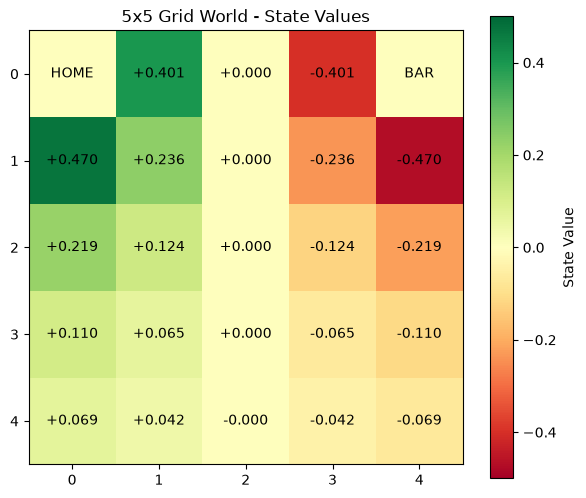

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# 딕셔너리의 가치를 5×5 배열로 변환
value_grid = np.array([
    [V[(r, c)] for c in range(SIZE)]
    for r in range(SIZE)
])

plt.figure(figsize=(7, 6))

plt.imshow(value_grid, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
plt.colorbar(label="State Value")

# 각 칸에 가치 표시
for r in range(SIZE):
    for c in range(SIZE):
        label = f"{value_grid[r, c]:+.3f}"

        if (r, c) == HOME:
            label = "HOME"
        elif (r, c) == BAR:
            label = "BAR"

        plt.text(c, r, label, ha="center", va="center")

plt.xticks(range(SIZE))
plt.yticks(range(SIZE))
plt.title("5x5 Grid World - State Values")
plt.grid(False)
plt.show()

- move(): 선택한 방향으로 이동하며, 격자 밖이면 제자리 유지
- get_reward(): Home 도착 +1, Bar 도착 -1, 나머지 0
- V: 각 좌표의 상태가치를 저장
- new_V: 벨만 기대 방정식으로 계산한 새로운 가치
- delta: 반복 전후 가치 변화량으로 수렴 여부 확인

실습 결과, Home과 가까운 왼쪽 영역은 양의 가치, Bar와 가까운 오른쪽 영역은 음의 가치가 나타남

가능한 모든 행동의 확률과 미래 보상을 반복 계산하여, 각 위치가 얼마나 유리한 상태인지 확인

### 문제
1. 상태 집합, 행동 집합, 종료 상태, 보상 규칙을 각각 한 문장으로 정리
2. 각 전이의 다음 상태, 보상, 종료 여부를 구하기
    - (1, 0)에서 up
    - (0, 1)에서 left
    - (0, 3)에서 right
    - (2, 0)에서 left
    - (0, 0)에서 down
3. 한 칸을 갱신하는 식이 왜 네 행동의 평균인지 설명. 종료상태로 들어갈 떄 다음 가치를 0으로 두는 이유도 포함
4. Home과 Bar의 가치가 처음부터 끝까지 0인 이유 코드의 두 지점과 연결해 설명
5. γ=0.95로 실행항 표에서 왼쪽이 양수이고 오른쪽이 음수이며 가운에 열이 0인 이유 설명
6. γ를 0.5로 낮추면 부호는 유지되는가? 절댓값은 어떻게 달라지는가?

1. 상태 및 규칙
    - 상태 집합(State): 5×5 격자의 모든 좌표 (행, 열)로 총 25개
    - 행동 집합(Action): 상(up), 하(down), 좌(left), 우(right) 네 방향 이동
    - 종료 상태(Terminal): Home (0, 0)과 Bar (0, 4)에 도착하면 종료
    - 보상 규칙(Reward): Home +1, Bar -1, 나머지 이동 0

2. 상태 전이 결과
    - (1, 0) up = 다음 상태 (0, 0) Home / 보상 +1 / 종료
    - (0, 1) left = 다음 상태 (0, 0) Home / 보상 +1 / 종료
    - (0, 3) right = 다음 상태 (0, 4) Bar / 보상 -1 / 종료
    - (2, 0) left = 다음 상태 (2, 0) / 보상 0 / 종료 X (격자 밖이므로 제자리)
    - (0, 0) down = 다음 상태 (0, 0) Home / 보상 0 / 이미 종료된 상태이므로 이동 X

3. 한 칸의 가치를 갱신할 때 왜 네 행동의 평균을 구하나요?
    - 상·하·좌·우를 각각 25% 확률로 선택하는 랜덤 정책이기 때문에 네 방향의 기대 가치를 평균 내는 것.
    - Home이나 Bar에 도착하면 게임이 종료되어 이후 보상이 없으므로 다음 상태의 가치는 0으로 계산.

4. Home과 Bar의 가치가 처음부터 끝까지 0인 이유는?
    - 처음부터 모든 상태가치를 0으로 초기화
        - V = {state: 0.0 for state in STATES}
    - 종료 상태는 가치 갱신을 건너뜀
        - if state in TERMINAL: continue
    - Home과 Bar는 종료 상태이므로 처음 설정한 0이 유지됨.
    - +1과 -1은 해당 칸에 도착할 때 받는 보상이므로 종료 상태 자체의 가치는 0.

5. γ=0.95에서 왼쪽은 양수, 오른쪽은 음수, 가운데 열은 0인 이유는?
    - 왼쪽: Home(+1)에 도착할 가능성이 상대적으로 높아 양수
    - 오른쪽: Bar(-1)에 도착할 가능성이 상대적으로 높아 음수
    - 가운데: Home과 Bar의 위치, 이동 확률, 보상이 좌우 대칭이므로 서로의 영향이 상쇄되어 0
    - 즉, 왼쪽은 긍정적인 보상, 오른쪽은 부정적인 보상의 영향을 더 많이 받으며 가운데는 두 영향이 같아지는 것이야.
    
6. γ를 0.5로 낮추면 부호와 절댓값은 어떻게 달라지나요?
    - 부호: 그대로 유지됨. 왼쪽은 양수, 오른쪽은 음수, 가운데는 0.
    - 절댓값: 감소함. 미래 보상을 더 많이 할인하기 때문.
    - 특징: Home과 Bar에서 멀리 떨어진 칸일수록 가치가 0에 가까워짐.